In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/housing.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (20640, 10)


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [8]:
print(df["ocean_proximity"].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage)


Missing Value Percentage:
longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64


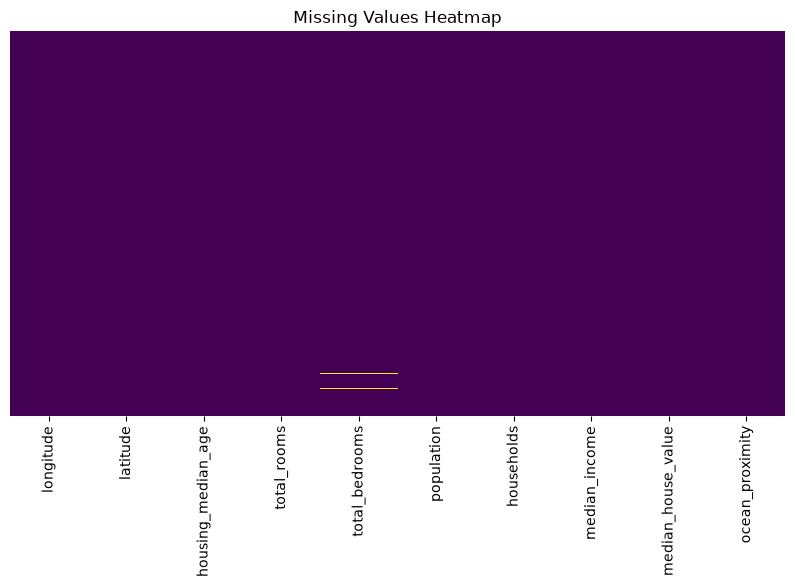

In [10]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")

plt.title("Missing Values Heatmap")
plt.show()

In [11]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

df["total_bedrooms"] = imputer.fit_transform(
    df[["total_bedrooms"]]
).ravel()

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


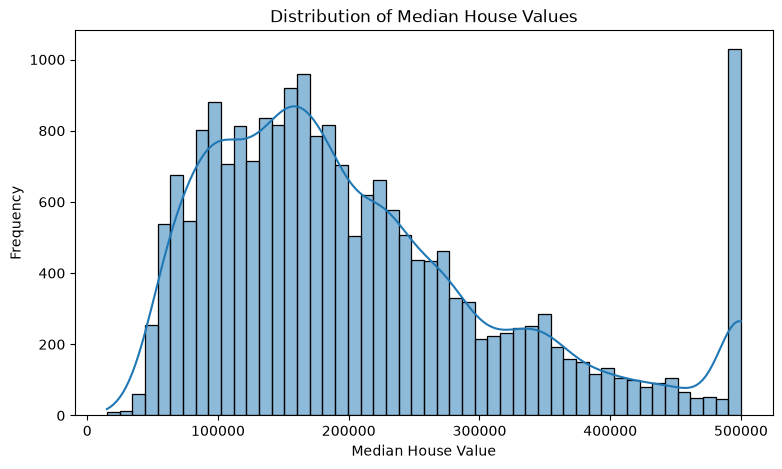

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(df["median_house_value"], bins=50, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

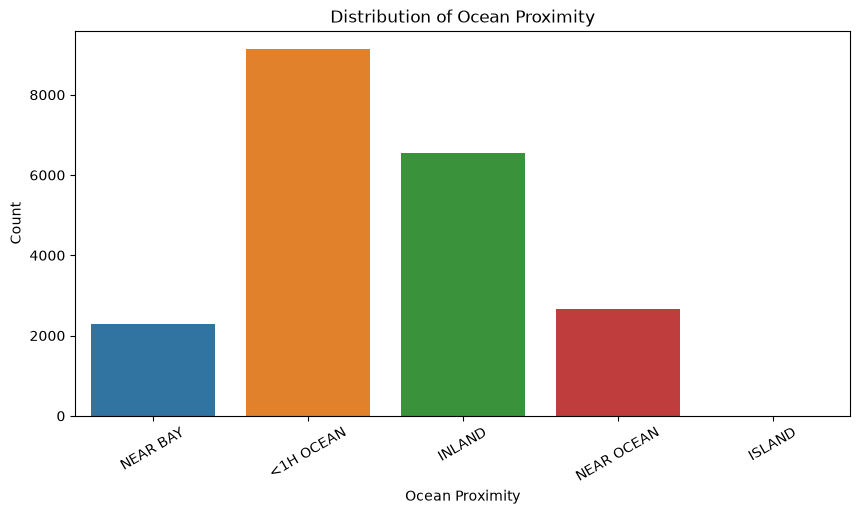

In [13]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="ocean_proximity", hue="ocean_proximity", legend=False)

plt.title("Distribution of Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Count")
plt.xticks(rotation=30)

plt.show()

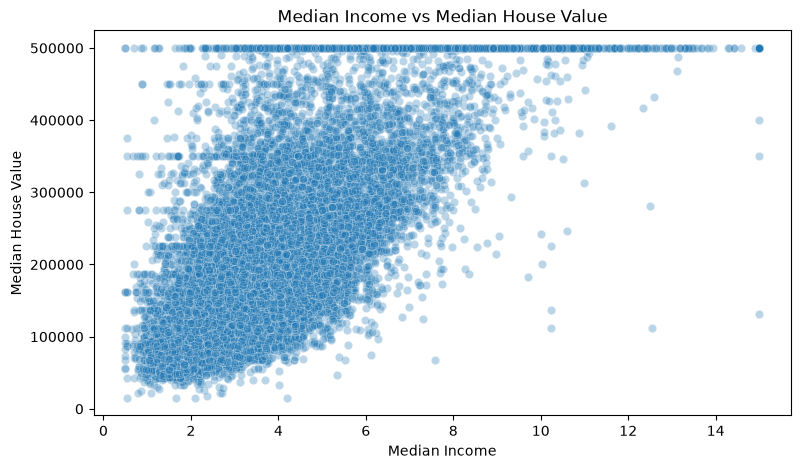

In [14]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

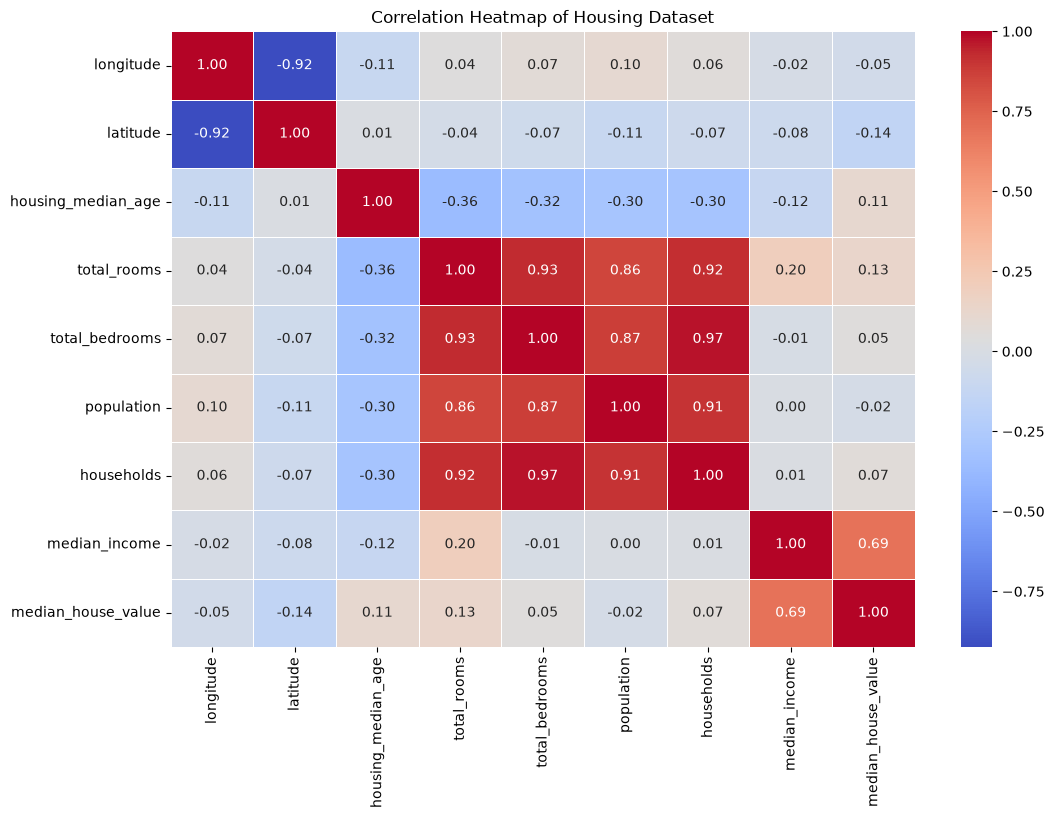

In [15]:
plt.figure(figsize=(12, 8))

correlation_matrix = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Housing Dataset")
plt.show()

In [16]:
!pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = df.select_dtypes(include=np.number).drop(
    columns=["median_house_value"]
)

X_vif = add_constant(X_vif)

vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif_data.sort_values(by="VIF", ascending=False))

              Feature        VIF
7          households  28.284141
5      total_bedrooms  26.882085
4         total_rooms  12.126382
2            latitude   8.826607
1           longitude   8.703623
6          population   6.261680
8       median_income   1.688920
3  housing_median_age   1.259064
0               const   1.000000


In [18]:
df = df.copy()

df["rooms_per_household"] = (
    df["total_rooms"] / df["households"].replace(0, np.nan)
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"].replace(0, np.nan)
)

df["population_per_household"] = (
    df["population"] / df["households"].replace(0, np.nan)
)

df["income_age_interaction"] = (
    df["median_income"] * df["housing_median_age"]
)

print("New features created successfully!")
print(df.head())

New features created successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  \
0       322.0       126.0         8.3252            452600.0        NEAR BAY   
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY   
2       496.0       177.0         7.2574            352100.0        NEAR BAY   
3       558.0       219.0         5.6431            341300.0        NEAR BAY   
4       565.0       259.0         3.8462            342200.0        NEAR BAY   

   rooms_per_household  bedrooms_

In [19]:
new_features = [
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_age_interaction"
]

print(df[new_features].describe())

       rooms_per_household  bedrooms_per_room  population_per_household  \
count         20640.000000       20640.000000              20640.000000   
mean              5.429000           0.213794                  3.070655   
std               2.474173           0.065248                 10.386050   
min               0.846154           0.037151                  0.692308   
25%               4.440716           0.175225                  2.429741   
50%               5.229129           0.203159                  2.818116   
75%               6.052381           0.240126                  3.282261   
max             141.909091           2.824675               1243.333333   

       income_age_interaction  
count            20640.000000  
mean               108.008027  
std                 74.386418  
min                  1.625000  
25%                 57.997425  
50%                 92.502950  
75%                140.104900  
max                780.005200  


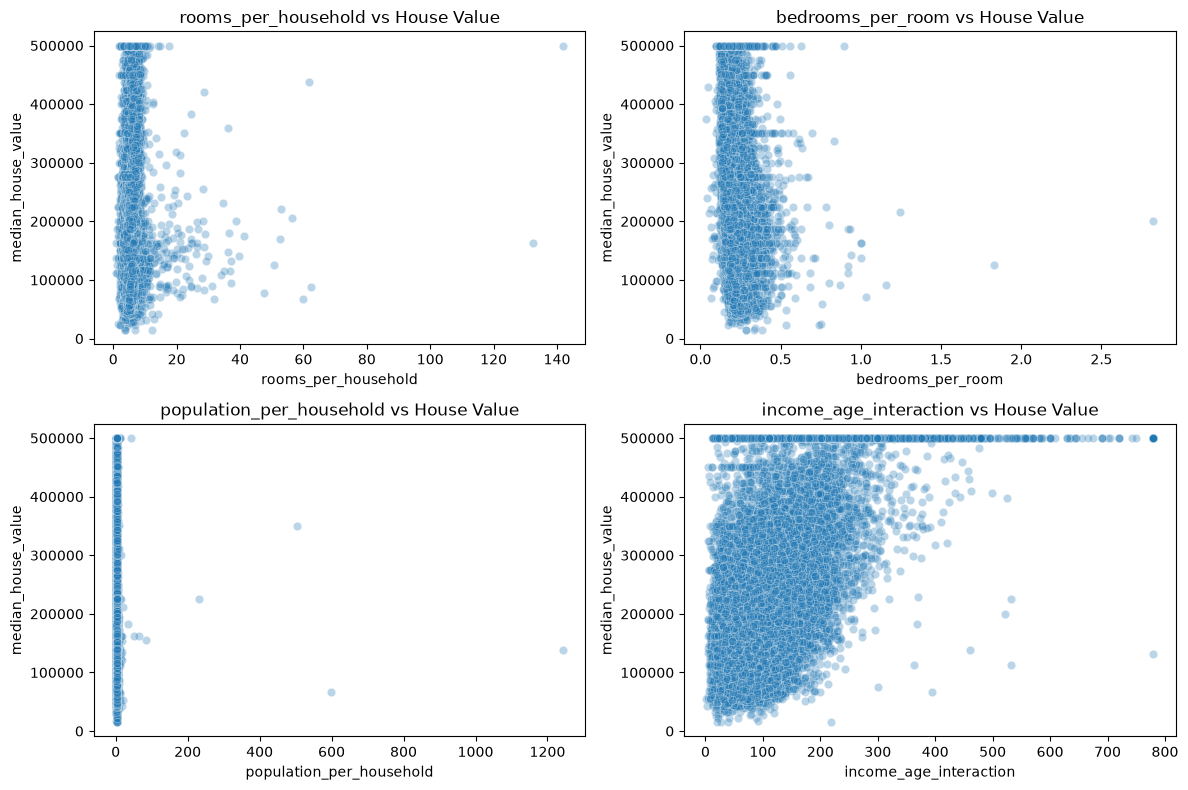

In [20]:
plt.figure(figsize=(12, 8))

for i, feature in enumerate(new_features, 1):
    plt.subplot(2, 2, i)
    sns.scatterplot(
        data=df,
        x=feature,
        y="median_house_value",
        alpha=0.3
    )
    plt.title(f"{feature} vs House Value")

plt.tight_layout()
plt.show()

In [21]:
df = pd.read_csv("../dataset/housing.csv")

print("Dataset shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())

Dataset shape: (20640, 10)
Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [22]:
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"].replace(0, np.nan)
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"].replace(0, np.nan)
)

df["population_per_household"] = (
    df["population"] / df["households"].replace(0, np.nan)
)

df["income_age_interaction"] = (
    df["median_income"] * df["housing_median_age"]
)

print("Feature engineering completed.")

Feature engineering completed.


In [23]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 13)
Target shape: (20640,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 13)
Testing data: (4128, 13)


In [25]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction']

Categorical features: ['ocean_proximity']


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [27]:
from sklearn.linear_model import LinearRegression

ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

ols_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [28]:
y_pred_ols = ols_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_ols[:10])

First 10 Actual Values:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 Predicted Values:
[ 37218.26384014 139754.90357    295755.21092525 280255.75113142
 264184.72967773 184663.37034283 275508.40921487 206458.80554528
 259016.81402999 426689.57846515]


In [29]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ols_mae = mean_absolute_error(y_test, y_pred_ols)
ols_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ols))
ols_r2 = r2_score(y_test, y_pred_ols)

print("OLS Linear Regression Results")
print("--------------------------------")
print("MAE:", round(ols_mae, 2))
print("RMSE:", round(ols_rmse, 2))
print("R2 Score:", round(ols_r2, 4))

OLS Linear Regression Results
--------------------------------
MAE: 49376.49
RMSE: 69048.19
R2 Score: 0.6362


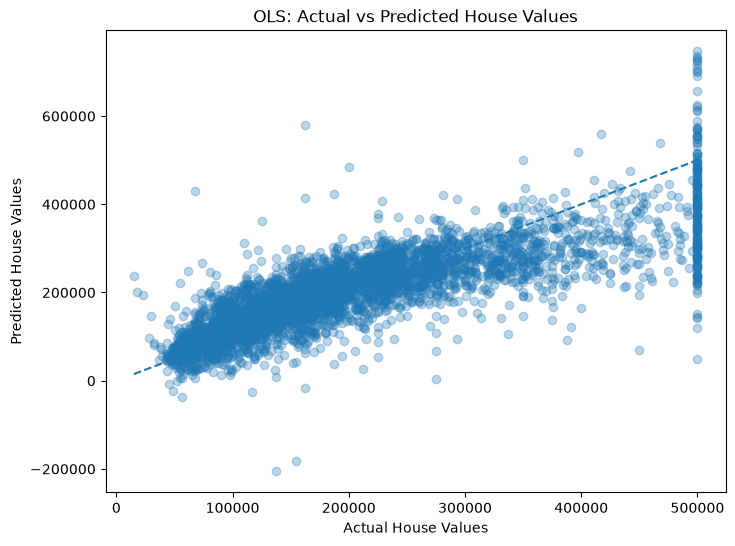

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_ols, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("OLS: Actual vs Predicted House Values")
plt.show()

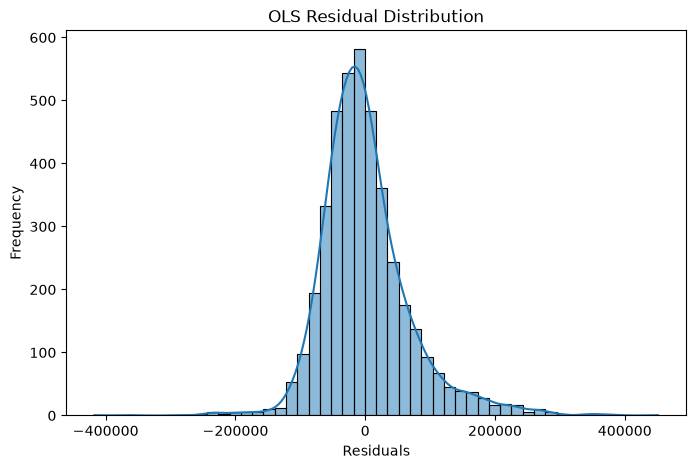

In [31]:
residuals_ols = y_test - y_pred_ols

plt.figure(figsize=(8, 5))

sns.histplot(residuals_ols, bins=50, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("OLS Residual Distribution")
plt.show()

In [32]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

print("Ridge Regression model trained successfully!")

Ridge Regression model trained successfully!


In [33]:
y_pred_ridge = ridge_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Ridge Predictions:")
print(y_pred_ridge[:10])

First 10 Actual Values:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 Ridge Predictions:
[ 37268.14324406 139665.12670714 295532.02556335 280218.9242978
 264156.27554251 184494.32071232 275589.99909642 206534.9346167
 258936.60712457 426738.8412087 ]


In [34]:
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Results")
print("-------------------------")
print("MAE:", round(ridge_mae, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R2 Score:", round(ridge_r2, 4))

Ridge Regression Results
-------------------------
MAE: 49382.63
RMSE: 69056.22
R2 Score: 0.6361


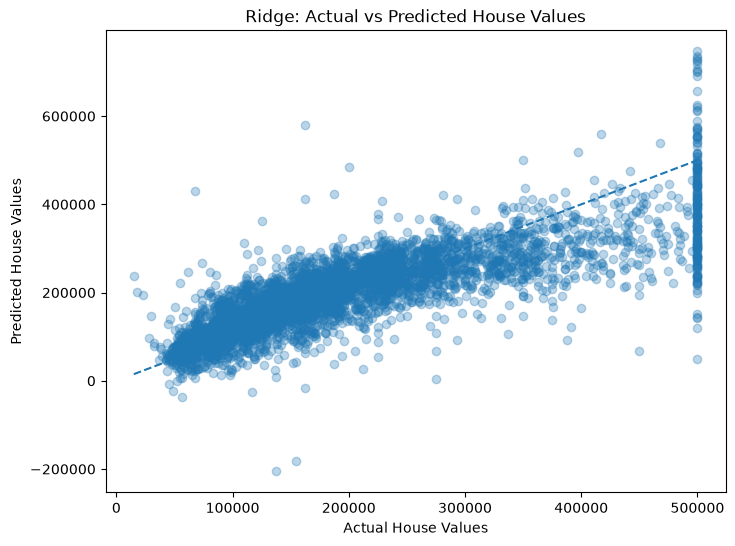

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_ridge, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Ridge: Actual vs Predicted House Values")
plt.show()

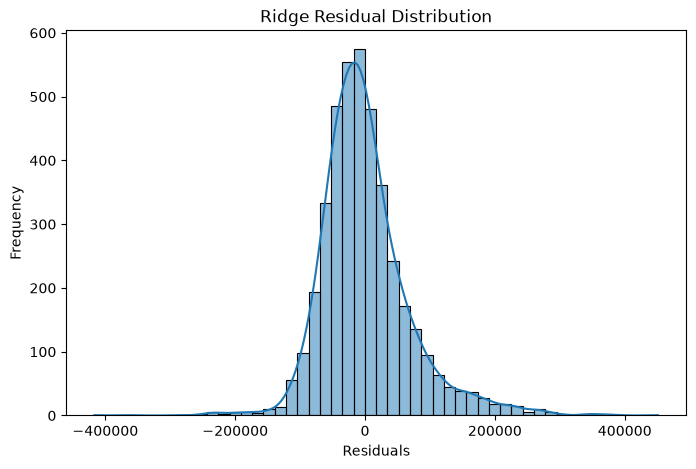

In [36]:
residuals_ridge = y_test - y_pred_ridge

plt.figure(figsize=(8, 5))

sns.histplot(residuals_ridge, bins=50, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Ridge Residual Distribution")
plt.show()


In [37]:
from sklearn.linear_model import Lasso

lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(alpha=1.0, max_iter=10000))
])

lasso_model.fit(X_train, y_train)

print("Lasso Regression model trained successfully!")

Lasso Regression model trained successfully!


In [38]:
y_pred_lasso = lasso_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Lasso Predictions:")
print(y_pred_lasso[:10])

First 10 Actual Values:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 Lasso Predictions:
[ 37233.61713624 139739.40362814 295722.88353898 280251.95725388
 264165.27760508 184644.26173596 275519.88770252 206471.89606331
 259017.15268412 426693.38832212]


In [39]:
lasso_mae = mean_absolute_error(y_test, y_pred_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_r2 = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Results")
print("-------------------------")
print("MAE:", round(lasso_mae, 2))
print("RMSE:", round(lasso_rmse, 2))
print("R2 Score:", round(lasso_r2, 4))

Lasso Regression Results
-------------------------
MAE: 49377.34
RMSE: 69049.25
R2 Score: 0.6362


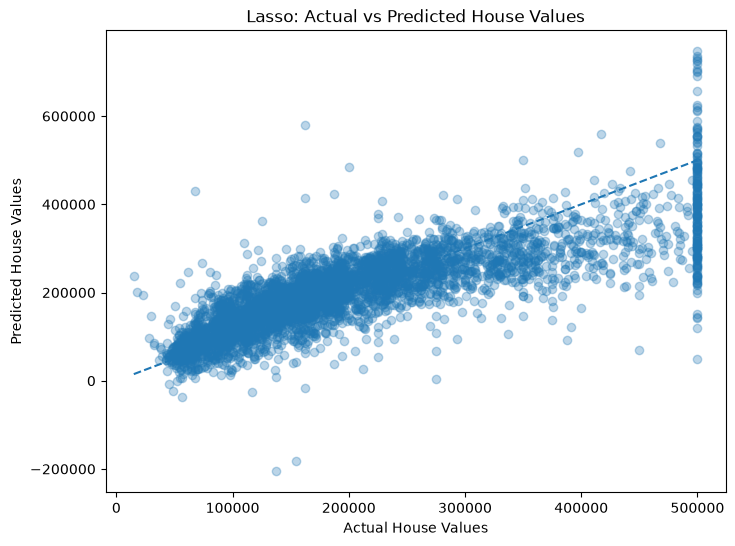

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lasso, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Lasso: Actual vs Predicted House Values")
plt.show()

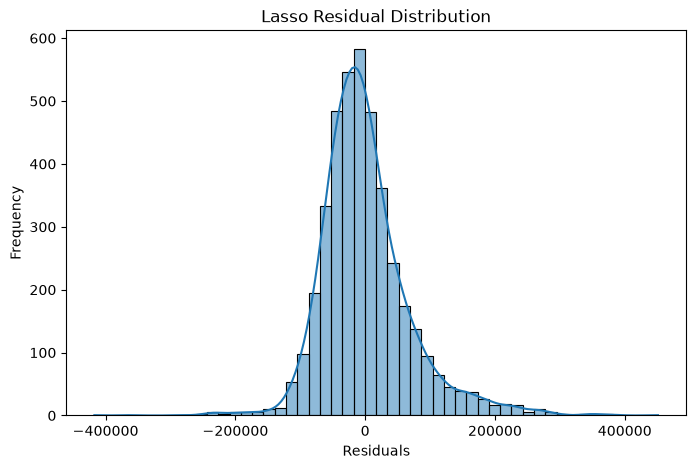

In [41]:
residuals_lasso = y_test - y_pred_lasso

plt.figure(figsize=(8, 5))

sns.histplot(residuals_lasso, bins=50, kde=True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Lasso Residual Distribution")
plt.show()

In [42]:
from sklearn.model_selection import GridSearchCV

alpha_values = {
    "regressor__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

print("Alpha values:", alpha_values)

Alpha values: {'regressor__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}


In [43]:
ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=alpha_values,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", round(-ridge_grid.best_score_, 2))

Best Ridge Alpha: {'regressor__alpha': 1}
Best Ridge CV RMSE: 67720.72


In [44]:
lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid=alpha_values,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", round(-lasso_grid.best_score_, 2))

Best Lasso Alpha: {'regressor__alpha': 1}
Best Lasso CV RMSE: 67721.65


In [45]:
best_ridge_model = ridge_grid.best_estimator_
best_lasso_model = lasso_grid.best_estimator_

y_pred_ridge_tuned = best_ridge_model.predict(X_test)
y_pred_lasso_tuned = best_lasso_model.predict(X_test)

print("Tuned Ridge Test RMSE:",
      round(np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned)), 2))

print("Tuned Lasso Test RMSE:",
      round(np.sqrt(mean_squared_error(y_test, y_pred_lasso_tuned)), 2))

Tuned Ridge Test RMSE: 69056.22
Tuned Lasso Test RMSE: 69049.25


In [46]:
tuned_results = pd.DataFrame({
    "Model": ["Tuned Ridge", "Tuned Lasso"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_ridge_tuned),
        mean_absolute_error(y_test, y_pred_lasso_tuned)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso_tuned))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred_ridge_tuned),
        r2_score(y_test, y_pred_lasso_tuned)
    ]
})

print(tuned_results.round(4))

         Model         MAE        RMSE  R2 Score
0  Tuned Ridge  49382.6281  69056.2204    0.6361
1  Tuned Lasso  49377.3433  69049.2483    0.6362


In [48]:
results = pd.DataFrame({
    "Model": [
        "OLS Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Tuned Ridge",
        "Tuned Lasso"
    ],
    "MAE": [
        ols_mae,
        ridge_mae,
        lasso_mae,
        mean_absolute_error(y_test, y_pred_ridge_tuned),
        mean_absolute_error(y_test, y_pred_lasso_tuned)
    ],
    "RMSE": [
        ols_rmse,
        ridge_rmse,
        lasso_rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso_tuned))
    ],
    "R2 Score": [
        ols_r2,
        ridge_r2,
        lasso_r2,
        r2_score(y_test, y_pred_ridge_tuned),
        r2_score(y_test, y_pred_lasso_tuned)
    ]
})

print(results.round(4))

                   Model         MAE        RMSE  R2 Score
0  OLS Linear Regression  49376.4886  69048.1923    0.6362
1       Ridge Regression  49382.6281  69056.2204    0.6361
2       Lasso Regression  49377.3433  69049.2483    0.6362
3            Tuned Ridge  49382.6281  69056.2204    0.6361
4            Tuned Lasso  49377.3433  69049.2483    0.6362


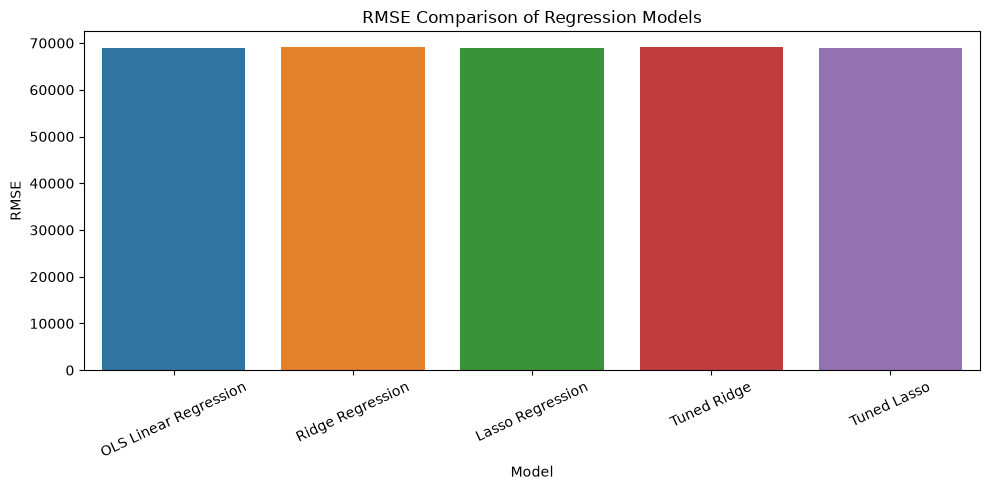

In [49]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE",
    hue="Model",
    legend=False
)

plt.title("RMSE Comparison of Regression Models")
plt.ylabel("RMSE")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

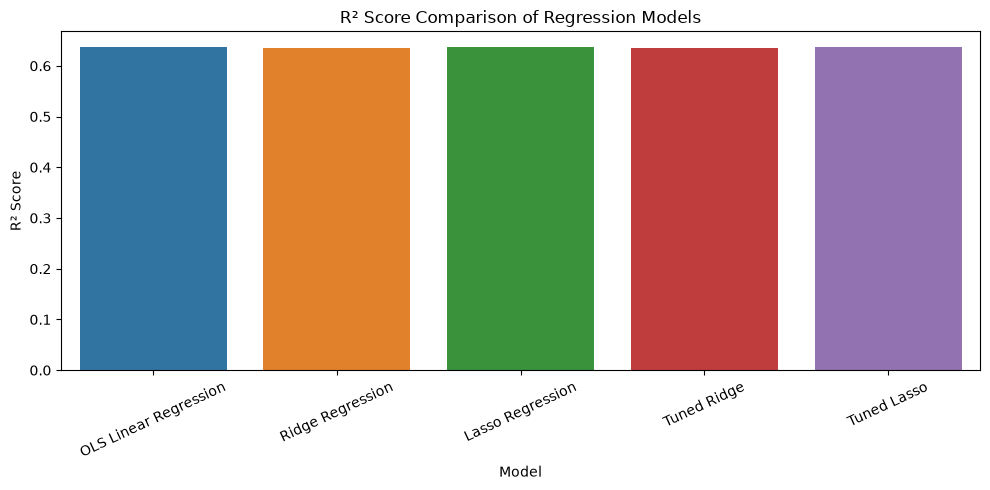

In [50]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score",
    hue="Model",
    legend=False
)

plt.title("R² Score Comparison of Regression Models")
plt.ylabel("R² Score")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [51]:
best_model_name = results.loc[results["RMSE"].idxmin(), "Model"]

print("Best Performing Model:", best_model_name)

print("\nBest Model Metrics:")
print(
    results.loc[results["RMSE"].idxmin()].to_string()
)

Best Performing Model: OLS Linear Regression

Best Model Metrics:
Model       OLS Linear Regression
MAE                  49376.488621
RMSE                 69048.192348
R2 Score                 0.636171


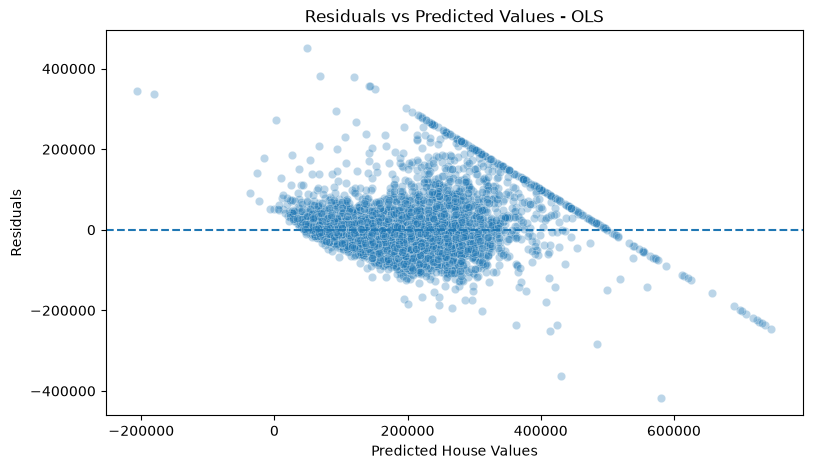

In [52]:
residuals = y_test - y_pred_ols

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=y_pred_ols,
    y=residuals,
    alpha=0.3
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values - OLS")
plt.show()

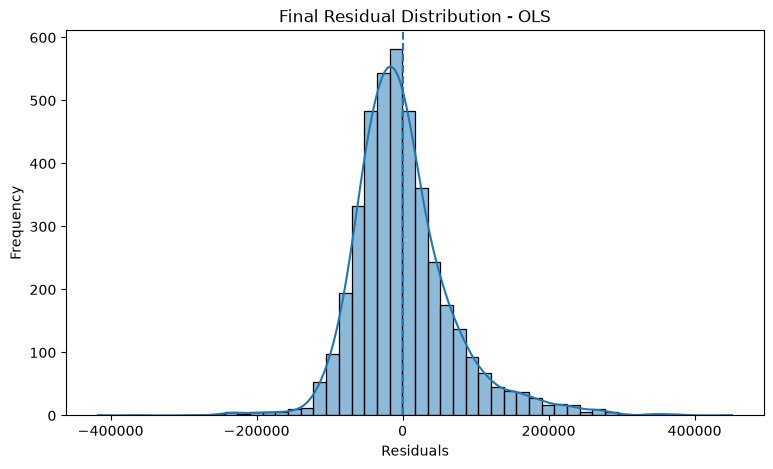

In [53]:
plt.figure(figsize=(9, 5))

sns.histplot(residuals, bins=50, kde=True)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Final Residual Distribution - OLS")
plt.show()

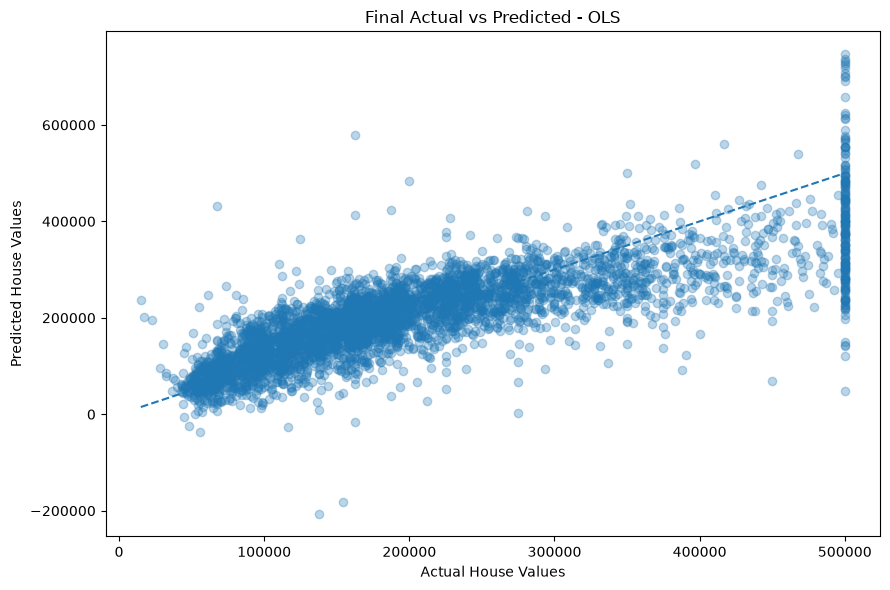

In [54]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred_ols, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Final Actual vs Predicted - OLS")
plt.tight_layout()
plt.show()

In [55]:
print("Final Residual Statistics")
print("-------------------------")
print("Mean Residual:", round(residuals.mean(), 2))
print("Standard Deviation:", round(residuals.std(), 2))
print("Minimum Residual:", round(residuals.min(), 2))
print("Maximum Residual:", round(residuals.max(), 2))

Final Residual Statistics
-------------------------
Mean Residual: 687.14
Standard Deviation: 69053.14
Minimum Residual: -417435.22
Maximum Residual: 451172.81


## Conclusion

In this project, I developed a machine learning solution to predict median house values using the California Housing dataset.

The project involved exploratory data analysis, missing-value imputation, feature engineering, categorical encoding, and feature scaling. Four regression approaches were investigated: Linear Regression (OLS), Ridge Regression, Lasso Regression, and hyperparameter-tuned Ridge and Lasso models using GridSearchCV.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

Among the evaluated models, **OLS Linear Regression achieved the best test performance**, with an MAE of 49,376.49, an RMSE of 69,048.19, and an R² score of 0.6362.

The results demonstrate that regularization did not provide a significant improvement over the baseline Linear Regression model for this dataset and feature configuration.

This project provided practical experience in regression modelling, feature engineering, data preprocessing, model evaluation, hyperparameter tuning, and residual analysis.